# County health need and relative care performance

This notebook is descriptive rather than predictive. It creates two county-level measures: the existing PLACES-based `NeedScore`, and a transparent `CarePerformanceScore` built from ER visits, acute readmissions, and standardized Medicare spending. The second measure supports comparison and visualization; it is not a causal measure of healthcare efficiency.

In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
county_need = pd.read_csv(PROJECT_ROOT / "data/processed/county_need_2024.csv")
cms24 = pd.read_csv(PROJECT_ROOT / "data/processed/cms24_county_small.csv")

In [33]:
county_need["CountyFIPS"] = (
    county_need["CountyFIPS"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)
cms24["BENE_GEO_CD"] = (
    cms24["BENE_GEO_CD"].astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

analysis_df = county_need.merge(
    cms24,
    left_on="CountyFIPS",
    right_on="BENE_GEO_CD",
    how="inner",
    validate="one_to_one",
)

metric_columns = [
    "NeedScore",
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
for column in metric_columns:
    analysis_df[column] = pd.to_numeric(
        analysis_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce",
    )

print(f"Merged counties: {len(analysis_df):,}")

Merged counties: 3,142


## Build the two axes

The care indicators are converted to z-scores so they share a common scale. Their signs are reversed because lower ER visits, readmissions, and spending are treated as relatively better on this descriptive axis. Higher `CarePerformanceScore` therefore means relatively lower combined utilization and spending. Inspect the individual indicators before making a substantive conclusion.

In [34]:
care_indicators = [
    "ER_VISITS_PER_1000_BENES",
    "ACUTE_HOSP_READMSN_PCT",
    "TOT_MDCR_STDZD_PYMT_PC",
]
score_df = analysis_df[
    ["StateAbbr", "CountyName", "CountyFIPS", "total_population", "NeedScore"]
    + care_indicators
].dropna().copy()

for column in care_indicators:
    score_df[f"{column}_z"] = (
        score_df[column] - score_df[column].mean()
    ) / score_df[column].std()

score_df["CarePerformanceScore"] = score_df[
    [f"{column}_z" for column in care_indicators]
].mul(-1).mean(axis=1)
score_df[["NeedScore", "CarePerformanceScore"]].describe().T

,count,mean,std,min,25%,50%,75%,max
NeedScore,2996.0,1.360233e+00,2.065968,-4.492298,-0.075007,1.162341,2.866045,9.314433
CarePerformanceScore,2996.0,1.849878e-16,0.747930,-4.610358,-0.441991,0.019198,0.472570,4.344204


## Visualize the four need/performance quadrants

Median cutoffs create a simple interpretation: high-need, lower-performance counties are priority candidates for closer investigation. This is a screening visualization, not a final ranking.

In [35]:
need_cutoff = score_df["NeedScore"].median()
performance_cutoff = score_df["CarePerformanceScore"].median()

def assign_quadrant(row):
    high_need = row["NeedScore"] >= need_cutoff
    high_performance = row["CarePerformanceScore"] >= performance_cutoff
    if high_need and not high_performance:
        return "High need / lower performance"
    if high_need and high_performance:
        return "High need / higher performance"
    if not high_need and high_performance:
        return "Lower need / higher performance"
    return "Lower need / lower performance"

score_df["Quadrant"] = score_df.apply(assign_quadrant, axis=1)
score_df["Priority"] = score_df["Quadrant"].eq("High need / lower performance")
score_df["Quadrant"].value_counts().to_frame("count")

,count
Quadrant,
Lower need / higher performance,970
High need / lower performance,970
High need / higher performance,528
Lower need / lower performance,528


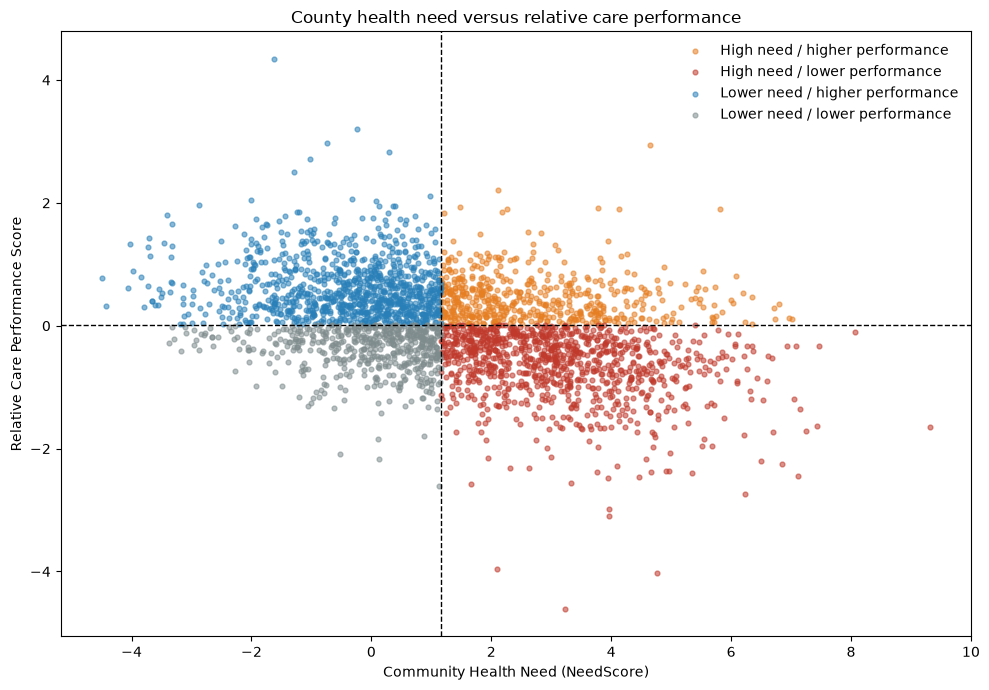

In [36]:
colors = {
    "High need / lower performance": "#c0392b",
    "High need / higher performance": "#e67e22",
    "Lower need / higher performance": "#2980b9",
    "Lower need / lower performance": "#7f8c8d",
}

fig, ax = plt.subplots(figsize=(10, 7))
for quadrant, group in score_df.groupby("Quadrant"):
    ax.scatter(
        group["NeedScore"],
        group["CarePerformanceScore"],
        s=12,
        alpha=0.55,
        label=quadrant,
        color=colors[quadrant],
    )
ax.axvline(need_cutoff, color="black", linestyle="--", linewidth=1)
ax.axhline(performance_cutoff, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Community Health Need (NeedScore)")
ax.set_ylabel("Relative Care Performance Score")
ax.set_title("County health need versus relative care performance")
ax.legend(frameon=False, loc="best")
plt.tight_layout()
plt.show()

In [37]:
priority_counties = (
    score_df[score_df["Priority"]]
    .sort_values(["NeedScore", "CarePerformanceScore"], ascending=[False, True])
    [[
        "StateAbbr", "CountyName", "CountyFIPS", "NeedScore",
        "CarePerformanceScore", *care_indicators,
    ]]
)
priority_counties.head(20)

,StateAbbr,CountyName,CountyFIPS,NeedScore,CarePerformanceScore,ER_VISITS_PER_1000_BENES,ACUTE_HOSP_READMSN_PCT,TOT_MDCR_STDZD_PYMT_PC
1112,KY,Wolfe,21237,9.314433,-1.641767,1002.0121,0.1569,15638.43
3090,WV,McDowell,54047,8.065461,-0.094288,764.1117,0.1657,10364.97
1167,LA,Tensas,22107,7.459349,-0.322819,622.5681,0.1579,14748.09
2413,SD,Oglala Lakota,46102,7.440376,-1.627824,601.8237,0.2380,17629.81
3093,WV,Mingo,54059,7.257157,-1.710376,860.5372,0.2750,11085.57
1131,LA,East Carroll,22035,7.142814,-1.355590,785.8473,0.1679,17177.08
2587,TX,Dimmit,48127,7.117166,-2.452746,890.9774,0.2471,16632.19
1067,KY,Magoffin,21153,7.080552,-0.331839,664.9810,0.1988,11434.53
1543,MS,Humphreys,28053,7.050507,-1.189404,658.9674,0.2273,14724.98
3070,WV,Calhoun,54013,6.934762,-0.329100,818.0708,0.1386,12480.44


## Check the composite for tradeoffs

The composite can hide an unusually high value on one indicator. Compare the individual distributions for priority and non-priority counties.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, care_indicators):
    score_df.boxplot(column=column, by="Priority", ax=ax, grid=False)
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Priority candidate")
    ax.set_ylabel("Value")
fig.suptitle("Care indicators for priority versus other counties")
plt.tight_layout()
plt.show()

In [38]:
score_df.to_csv(
    PROJECT_ROOT / "data/processed/county_need_performance_quadrants_2024.csv",
    index=False,
)